## Импорт зависимостей

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

## Объявление констант и форматов pandas

In [3]:
PROJECT_DIR = Path.cwd().parent
RAW_DATA_DIR = PROJECT_DIR / 'data' / 'raw'

RANDOM_SEED = 42
SHUFFLE = True
TARGET = 'fraud_bool'

pd.set_option('display.max_columns',1000)
pd.set_option('display.max_rows', 100)

## Загрузка данных

In [4]:
full_raw_data = pd.read_csv(RAW_DATA_DIR / 'Base.csv')

In [5]:
full_raw_data.head()

,fraud_bool,income,name_email_similarity,prev_address_months_count,current_address_months_count,customer_age,days_since_request,intended_balcon_amount,payment_type,zip_count_4w,velocity_6h,velocity_24h,velocity_4w,bank_branch_count_8w,date_of_birth_distinct_emails_4w,employment_status,credit_risk_score,email_is_free,housing_status,phone_home_valid,phone_mobile_valid,bank_months_count,has_other_cards,proposed_credit_limit,foreign_request,source,session_length_in_minutes,device_os,keep_alive_session,device_distinct_emails_8w,device_fraud_count,month
0,0,0.3,0.986506,-1,25,40,0.006735,102.453711,AA,1059,13096.035018,7850.955007,6742.080561,5,5,CB,163,1,BC,0,1,9,0,1500.0,0,INTERNET,16.224843,linux,1,1,0,0
1,0,0.8,0.617426,-1,89,20,0.010095,-0.849551,AD,1658,9223.283431,5745.251481,5941.664859,3,18,CA,154,1,BC,1,1,2,0,1500.0,0,INTERNET,3.363854,other,1,1,0,0
2,0,0.8,0.996707,9,14,40,0.012316,-1.490386,AB,1095,4471.472149,5471.988958,5992.555113,15,11,CA,89,1,BC,0,1,30,0,200.0,0,INTERNET,22.730559,windows,0,1,0,0
3,0,0.6,0.475100,11,14,30,0.006991,-1.863101,AB,3483,14431.993621,6755.344479,5970.336831,11,13,CA,90,1,BC,0,1,1,0,200.0,0,INTERNET,15.215816,linux,1,1,0,0
4,0,0.9,0.842307,-1,29,40,5.742626,47.152498,AA,2339,7601.511579,5124.046930,5940.734212,1,6,CA,91,0,BC,1,1,26,0,200.0,0,INTERNET,3.743048,other,0,1,0,0


## Первичный аудит данных

### Какие типы данных у ячеек и что они значат:

- fraud_bool                            int64 - целевая переменная - является ли операция мошеннической или нет
- income                              float64 - годовой доход выраженный в квантилях(ранжируется от 0 до 1)
- name_email_similarity               float64 - мера сходства имени и email(ранжируется от 0 до 1)
- prev_address_months_count             int64 - месяцы, проведенные на предыдущем месте регистрации(если стоит -1, то неизвестно) - проверка на -1 - признак знания времени проживания на предыдущем месте
- current_address_months_count          int64 - месяцы, проведенные на текущем месте регистрации (если стоит -1, то неизвестно) - проверка на -1 - признак знания времени проживания на текущем месте
- customer_age                          int64 - возраст человека(в декадах: если значение в пределах 20-29, то значение 20)
- days_since_request                  float64 - дни с момента отправки заявки
- intended_balcon_amount              float64 - сколько условных единиц денег клиент собирается положить при открытии счёта (-1 - неизвестно) - проверка на -1
- payment_type                            str - просто категориальный признак - не париться, тк описания нет
- zip_count_4w                          int64 - кол-во заявок в пределах одного почтового индекса за последний месяц
- velocity_6h                         float64 - среднее кол-во заявок за 6 часов
- velocity_24h                        float64 - среднее кол-во заявок за 24 часа
- velocity_4w                         float64 - среднее кол-во заявок за 4 недели
Для velocity можно добавить пересчёт значений для сравнения меньшего временного отрезка(6 часов) с соответственно разделенным количеством за больший временной отрезок(сравнение кол-ва за 6 часов с кол-вом за 24 часа деленым на 4)
- bank_branch_count_8w                  int64 - кол-во заявок в выбранное отделение банка
- date_of_birth_distinct_emails_4w      int64 - кол-во писем, отправленных заявителем с одинаковой датой рождения за последине 4 недели
- employment_status                       str - статус трудоустройства - просто кат. признак без конкретной расшифровки
- credit_risk_score                     int64 - кредитный рейтинг
- email_is_free                         int64 - бинарный признак - оплачивается ли доступ к email у заявителя
- housing_status                          str - очередной анонимизированный кат. признак
- phone_home_valid                      int64 - бинарный признак - достоверность предоставленного номера телефона(домашнего)
- phone_mobile_valid                    int64 - бинарный признак - достоверность предоставленного номера мобильного телефона
- bank_months_count                     int64 - сколько месяцев другому банковскому аккаунту (-1 - неизвестно) - добавить проверку
- has_other_cards                       int64 - бинарный признак - есть ли у человека карты той 
- proposed_credit_limit               float64 - оценка максимального кредита человеку 
- foreign_request                       int64 - бинарный признак -отличается ли страна заявителя от страны, в которой находится банк
- source                                  str - кат. признак - заявка на сайте или с телефона
- session_length_in_minutes           float64 - длина сессии заявителя на сайте при подаче заявки (-1 - неизвестно - добавить проверку)
- device_os                               str - операционка, с которой отправлен запрос
- keep_alive_session                    int64 - бинарный признак - остался ли пользователь в аккаунте после завершения заявки
- device_distinct_emails_8w             int64 - количество уникальных адресов почты, с которых входили на аккаунт с выбранного устройства
- device_fraud_count                    int64 - количество мошеннических заявок с выбранного телефона
- month                                 int64 - месяц наблюдений

In [6]:
print('shape is', full_raw_data.shape)
full_raw_data.dtypes

shape is (1000000, 32)


fraud_bool                            int64
income                              float64
name_email_similarity               float64
prev_address_months_count             int64
current_address_months_count          int64
customer_age                          int64
days_since_request                  float64
intended_balcon_amount              float64
payment_type                            str
zip_count_4w                          int64
velocity_6h                         float64
velocity_24h                        float64
velocity_4w                         float64
bank_branch_count_8w                  int64
date_of_birth_distinct_emails_4w      int64
employment_status                       str
credit_risk_score                     int64
email_is_free                         int64
housing_status                          str
phone_home_valid                      int64
phone_mobile_valid                    int64
bank_months_count                     int64
has_other_cards                 

### Анализ распределения целевой переменной

In [7]:
full_raw_data['fraud_bool'].value_counts(normalize=True), full_raw_data['fraud_bool'].value_counts()

(fraud_bool
 0    0.988971
 1    0.011029
 Name: proportion, dtype: float64,
 fraud_bool
 0    988971
 1     11029
 Name: count, dtype: int64)

Целевая переменная имеет большой разброс, где на миллион записей приходится 98.9 корректных операций и 1.1 мошеннических

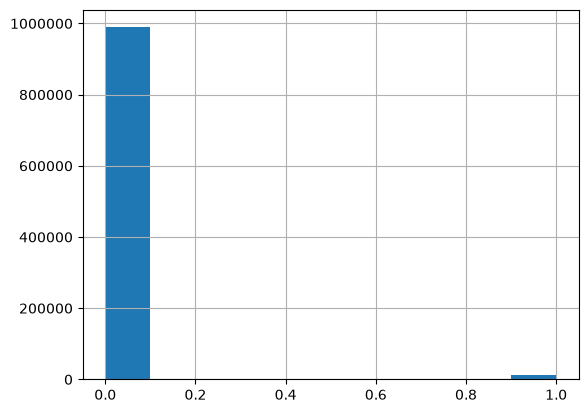

In [8]:
full_raw_data['fraud_bool'].hist()
plt.ticklabel_format(style='plain')
plt.show()

In [9]:
not_scam, scam = full_raw_data['fraud_bool'].value_counts()

In [10]:
for month_num in range(0,8):
    month_df = full_raw_data[full_raw_data['month'] == month_num]
    monthly_not_scam, monthly_scam = month_df['fraud_bool'].value_counts()
    print(f'Month: {month_num}')
    print(f'Not scam: {monthly_not_scam} / {(monthly_not_scam/(monthly_not_scam+monthly_scam)):.4f}')
    print(f'Scam:     {monthly_scam} / {(monthly_scam/(monthly_not_scam+monthly_scam)):.4f}')
    print(f'% Of All Scam: {(monthly_scam/scam):.3f}')
    print()
    

Month: 0
Not scam: 130940 / 0.9887
Scam:     1500 / 0.0113
% Of All Scam: 0.136

Month: 1
Not scam: 126422 / 0.9906
Scam:     1198 / 0.0094
% Of All Scam: 0.109

Month: 2
Not scam: 135781 / 0.9913
Scam:     1198 / 0.0087
% Of All Scam: 0.109

Month: 3
Not scam: 149544 / 0.9908
Scam:     1392 / 0.0092
% Of All Scam: 0.126

Month: 4
Not scam: 126239 / 0.9886
Scam:     1452 / 0.0114
% Of All Scam: 0.132

Month: 5
Not scam: 117912 / 0.9882
Scam:     1411 / 0.0118
% Of All Scam: 0.128

Month: 6
Not scam: 106718 / 0.9866
Scam:     1450 / 0.0134
% Of All Scam: 0.131

Month: 7
Not scam: 95415 / 0.9853
Scam:     1428 / 0.0147
% Of All Scam: 0.129



**Аналог той же операции в более правильном виде**

In [11]:
monthly_fraud_stats = (
    full_raw_data.groupby('month', as_index=False).agg(
        applications=('fraud_bool','size'),
        fraud_count=('fraud_bool','sum'),
        fraud_rate=('fraud_bool','mean'),
        ).sort_values('month'))

monthly_fraud_stats['legit_count'] = (
    monthly_fraud_stats['applications'] - monthly_fraud_stats['fraud_count']
)

total_fraud = monthly_fraud_stats['fraud_count'].sum()

monthly_fraud_stats['share_of_all_fraud'] = (monthly_fraud_stats['fraud_count']/ total_fraud)

monthly_fraud_stats

,month,applications,fraud_count,fraud_rate,legit_count,share_of_all_fraud
0,0,132440,1500,0.011326,130940,0.136005
1,1,127620,1198,0.009387,126422,0.108623
2,2,136979,1198,0.008746,135781,0.108623
3,3,150936,1392,0.009222,149544,0.126213
4,4,127691,1452,0.011371,126239,0.131653
5,5,119323,1411,0.011825,117912,0.127935
6,6,108168,1450,0.013405,106718,0.131472
7,7,96843,1428,0.014746,95415,0.129477


По соотношению мошенников к немошенникам:
С 0 по 2 месяц наблюдается уменьшение доли мошеннических операций, также как и тенденцию спада их количества
с 3 по конец наблюдений видно увеличение доли мошеннических операций, также как и тендецию роста их количества

### Подсчет дубликатов, пропусков и -1 значений для каждой колонки

In [12]:
data_audit = pd.DataFrame({
    'dtype': full_raw_data.dtypes.astype(str),
    'rows': len(full_raw_data),
    'unique': full_raw_data.nunique(),
    'duplicated': full_raw_data.apply(lambda col: col.duplicated().sum()),
    'missing': full_raw_data.isna().sum(),
    '-1': full_raw_data.eq(-1).sum()
})

data_audit['missing_%'] = data_audit['missing']/data_audit['rows'] * 100
data_audit['-1_%'] = data_audit['-1']/data_audit['rows'] * 100

data_audit

,dtype,rows,unique,duplicated,missing,-1,missing_%,-1_%
fraud_bool,int64,1000000,2,999998,0,0,0.0,0.0000
income,float64,1000000,9,999991,0,0,0.0,0.0000
name_email_similarity,float64,1000000,998861,1139,0,0,0.0,0.0000
prev_address_months_count,int64,1000000,374,999626,0,712920,0.0,71.2920
current_address_months_count,int64,1000000,423,999577,0,4254,0.0,0.4254
customer_age,int64,1000000,9,999991,0,0,0.0,0.0000
days_since_request,float64,1000000,989330,10670,0,0,0.0,0.0000
intended_balcon_amount,float64,1000000,994971,5029,0,0,0.0,0.0000
payment_type,str,1000000,5,999995,0,0,0.0,0.0000
zip_count_4w,int64,1000000,6306,993694,0,0,0.0,0.0000


Выводы по сводной статистике:
- NA пропусков нет ни в одной колонке
- -1 - "Неизвестно" пропуски есть в:
    1. prev_address_months_count - 712920
    2. current_address_months_count - 4254
    3. credit_risk_score - 488	
    4. bank_months_count - 253635
    5. session_length_in_minutes - 2015
    6. device_distinct_emails_8w - 359

Надо подумать, как кодировать это значение потом. В baseline не буду импутировать какое-либо значение, а потом уже поэкспериментриую 

- Полных строчных дубликатов в таблице нет
- Дубликаты по каждой отдельной переменной логичны и некритичны: где-то значение вещественное и почти не имеет дубликатов даже на 1000000 строчек, а какие-то несут булевый смысл и 999998 дубликатов логичны(тк в целом возможных значений всего 2)

## По поводу предупреждения утечки через исключение признаков

Исключить точно:
- целевую переменную
- days_since_request? - мне кажется, что эта переменная получается спустя время(непонятно ее значение в контексте момента сбора данных)
- keep_alive_session? - небольшое сомнение в сторону того, чтобы убрать есть, хотя в целом, если экран выбора сохранения сессии сразу после заявки, то всё ок
- month - не уверен - ранее не работал с временными данными - но делить по month определенно надо будет

## Анализ распределения переменных

In [14]:
## Базовый простой вариант
numeric_stats = full_raw_data.groupby('month').describe()
numeric_stats

fraud_bool                                                 income  \
           count      mean       std  min  25%  50%  75%  max     count   
month                                                                     
0       132440.0  0.011326  0.105819  0.0  0.0  0.0  0.0  1.0  132440.0   
1       127620.0  0.009387  0.096432  0.0  0.0  0.0  0.0  1.0  127620.0   
2       136979.0  0.008746  0.093110  0.0  0.0  0.0  0.0  1.0  136979.0   
3       150936.0  0.009222  0.095590  0.0  0.0  0.0  0.0  1.0  150936.0   
4       127691.0  0.011371  0.106028  0.0  0.0  0.0  0.0  1.0  127691.0   
5       119323.0  0.011825  0.108099  0.0  0.0  0.0  0.0  1.0  119323.0   
6       108168.0  0.013405  0.115002  0.0  0.0  0.0  0.0  1.0  108168.0   
7        96843.0  0.014746  0.120533  0.0  0.0  0.0  0.0  1.0   96843.0   

                                                   name_email_similarity  \
           mean       std  min  25%  50%  75%  max                 count   
month                                                                      
0      0.545999  0.288829  0.1  0.3  0.6  0.8  0.9              132440.0   
1      0.520698  0.293634  0.1  0.2  0.6  0.8  0.9              127620.0   
2      0.496552  0.293966  0.1  0.2  0.5  0.8  0.9              136979.0   
3      0.563151  0.290579  0.1  0.3  0.6  0.8  0.9              150936.0   
4      0.580703  0.287667  0.1  0.3  0.7  0.8  0.9              127691.0   
5      0.580014  0.285162  0.1  0.3  0.6  0.8  0.9              119323.0   
6      0.626423  0.274870  0.1  0.4  0.7  0.9  0.9              108168.0   
7      0.617458  0.279313  0.1  0.4  0.7  0.9  0.9               96843.0   

                                                                             \
           mean       std       min       25%       50%       75%       max   
month                                                                         
0      0.480271  0.288293  0.000082  0.196917  0.500720  0.733616  0.999999   
1      0.526254  0.278439  0.000019  0.297806  0.535629  0.770708  0.999999   
2      0.536123  0.289807  0.000023  0.292039  0.536535  0.819083  0.999999   
3      0.485859  0.299502  0.000001  0.199389  0.472355  0.766308  0.999999   
4      0.490350  0.294146  0.000019  0.217589  0.473079  0.762018  0.999996   
5      0.473809  0.286846  0.000042  0.211758  0.431292  0.734945  0.999998   
6      0.462752  0.286655  0.000103  0.205105  0.411215  0.724938  0.999999   
7      0.484813  0.274916  0.000038  0.252219  0.487240  0.708949  0.999996   

      prev_address_months_count                                             \
                          count       mean        std  min  25%  50%   75%   
month                                                                        
0                      132440.0  17.995500  45.941439 -1.0 -1.0 -1.0  19.0   
1                      127620.0  13.645886  40.680970 -1.0 -1.0 -1.0  -1.0   
2                      136979.0  18.444623  45.062508 -1.0 -1.0 -1.0  24.0   
3                      150936.0  20.081637  47.495146 -1.0 -1.0 -1.0  26.0   
4                      127691.0  16.521697  44.857970 -1.0 -1.0 -1.0  12.0   
5                      119323.0   9.938302  35.486829 -1.0 -1.0 -1.0  -1.0   
6                      108168.0  15.095010  41.910458 -1.0 -1.0 -1.0  -1.0   
7                       96843.0  21.765652  47.849883 -1.0 -1.0 -1.0  29.0   

             current_address_months_count                                    \
         max                        count        mean        std  min   25%   
month                                                                         
0      364.0                     132440.0   85.359333  89.467408 -1.0  18.0   
1      367.0                     127620.0  100.431257  96.141979 -1.0  29.0   
2      372.0                     136979.0   80.539418  88.732192 -1.0  15.0   
3      374.0                     150936.0   79.237511  87.326322 -1.0  14.0   
4      377.0                     127691.0   90.412261  91.436

In [15]:
numeric_cols = (full_raw_data.select_dtypes(include='number').columns.drop(['month','fraud_bool']))

improved_numeric_stats = (
    full_raw_data[numeric_cols]
    .mask(full_raw_data[numeric_cols] == -1)
    .groupby(full_raw_data["month"])
    .agg(["mean", "median", "std", "min", "max"])
)

improved_numeric_stats

income                            name_email_similarity            \
           mean median       std  min  max                  mean    median   
month                                                                        
0      0.545999    0.6  0.288829  0.1  0.9              0.480271  0.500720   
1      0.520698    0.6  0.293634  0.1  0.9              0.526254  0.535629   
2      0.496552    0.5  0.293966  0.1  0.9              0.536123  0.536535   
3      0.563151    0.6  0.290579  0.1  0.9              0.485859  0.472355   
4      0.580703    0.7  0.287667  0.1  0.9              0.490350  0.473079   
5      0.580014    0.6  0.285162  0.1  0.9              0.473809  0.431292   
6      0.626423    0.7  0.274870  0.1  0.9              0.462752  0.411215   
7      0.617458    0.7  0.279313  0.1  0.9              0.484813  0.487240   

                                    prev_address_months_count         \
            std       min       max                      mean median   
month                                                                  
0      0.288293  0.000082  0.999999                 62.372563   33.0   
1      0.278439  0.000019  0.999999                 59.348315   32.0   
2      0.289807  0.000023  0.999999                 56.589297   31.0   
3      0.299502  0.000001  0.999999                 58.478448   31.0   
4      0.294146  0.000019  0.999996                 62.307858   33.0   
5      0.286846  0.000042  0.999998                 61.728457   35.0   
6      0.286655  0.000103  0.999999                 63.780093   45.0   
7      0.274916  0.000038  0.999996                 64.539820   50.0   

                             current_address_months_count                    \
             std  min    max                         mean median        std   
month                                                                         
0      65.032120  6.0  364.0                    85.758932   49.0  89.480646   
1      63.727484  6.0  367.0                   100.704605   64.0  96.126943   
2      61.785483  6.0  372.0                    80.923381   48.0  88.763853   
3      63.879550  5.0  374.0                    79.618877   44.0  87.357809   
4      66.120215  6.0  377.0                    90.784601   54.0  91.436157   
5      63.033914  6.0  373.0                    95.562058   67.0  83.872612   
6      62.576840  7.0  383.0                    90.114636   60.0  84.225017   
7      61.548141  6.0  381.0                    71.187807   39.0  78.530046   

                  customer_age                           days_since_request  \
       min    max         mean median        std min max               mean   
month                                                                         
0      0.0  418.0    33.566898   30.0  12.427547  10  90           0.721744   
1      0.0  425.0    33.093637   30.0  12.136599  10  90           1.346258   
2      0.0  417.0    33.664503   30.0  11.912297  10  90           1.511642   
3      0.0  425.0    34.426711   30.0  11.685183  10  90           0.996418   
4      0.0  412.0    33.537916   30.0  12.331696  10  90           1.141969   
5      0.0  414.0    33.557068   30.0  12.069731  10  90           0.639925   
6      0.0  428.0    34.417388   30.0  12.248443  10  90           0.860065   
7      0.0  399.0    33.074461   30.0  11.161279  10  90           0.884328   

                                                   intended_balcon_amount  \
         median       std           min        max                   mean   
month                                                                       
0      0.014717  4.174285  4.036860e-09  75.554325              10.320819   
1      0.015180  5.466546  3.112791e-08  76.581477               8.377181   
2      0.016260  6.119567  4.284950e-08  75.989327               9.040804   
3      0.015997  5.436421  3.176904e-07  76.296635              10.338422   
4      0.014701  6.127789  9.943648e-08  75.969657               7.247711   
5

In [16]:
monthly_mean = full_raw_data[full_raw_data != -1].groupby('month')[numeric_cols].mean()
mean_delta = monthly_mean - monthly_mean.loc[0]
mean_delta.loc[0] = monthly_mean.loc[0]
mean_delta

,income,name_email_similarity,prev_address_months_count,current_address_months_count,customer_age,days_since_request,intended_balcon_amount,zip_count_4w,velocity_6h,velocity_24h,velocity_4w,bank_branch_count_8w,date_of_birth_distinct_emails_4w,credit_risk_score,email_is_free,phone_home_valid,phone_mobile_valid,bank_months_count,has_other_cards,proposed_credit_limit,foreign_request,session_length_in_minutes,keep_alive_session,device_distinct_emails_8w,device_fraud_count
month,,,,,,,,,,,,,,,,,,,,,,,,,
0,0.545999,0.480271,62.372563,85.758932,33.566898,0.721744,10.320819,2168.830384,7436.980252,5882.409562,6189.182587,197.373007,11.567132,117.348308,0.571549,0.412647,0.896927,14.268938,0.170757,591.471685,0.039709,8.232482,0.677582,1.026185,0.0
1,-0.025301,0.045983,-3.024248,14.945673,-0.473261,0.624513,-1.943638,-492.656665,-615.570148,-337.663772,-796.958540,4.089922,-1.174592,-8.192419,0.016321,0.010413,-0.036968,1.006048,0.038019,-68.504439,-0.018952,-0.118854,-0.086938,0.009447,0.0
2,-0.049447,0.055852,-5.783266,-4.835551,0.097605,0.789898,-1.280015,-455.241892,-971.569811,-588.874116,-832.880298,-19.994116,-1.390280,-5.769793,-0.042753,-0.052205,-0.024844,1.499427,0.004438,-139.969630,-0.017428,0.628098,-0.117715,0.008746,0.0
3,0.017152,0.005588,-3.894115,-6.140055,0.859812,0.274673,0.017603,-627.730639,-1476.822887,-909.784192,-1275.582326,-2.464151,-1.942305,28.533345,-0.019229,-0.066183,-0.006980,0.266809,0.101564,-1.972361,-0.017023,-0.745972,-0.157117,-0.015920,0.0
4,0.034704,0.010079,-0.064705,5.025669,-0.028982,0.420225,-3.073108,-607.721566,-2113.648246,-1269.824767,-1549.014900,-13.897452,-2.108126,19.658350,-0.081405,-0.012556,-0.016434,0.921348,0.073544,-83.853451,-0.013152,-1.176464,-0.197071,-0.014763,0.0
5,0.034015,-0.006462,-0.644106,9.803126,-0.009830,-0.081819,-2.597611,-750.430905,-2681.139985,-1663.722030,-1904.566852,-3.824780,-2.908500,24.972194,-0.054155,0.093911,0.015890,0.400618,0.103390,-112.697518,-0.015505,-1.624201,-0.085098,-0.014860,0.0
6,0.080424,-0.017520,1.407530,4.355704,0.850490,0.138320,-0.745638,-872.986456,-3478.380278,-2190.902860,-2069.956545,-3.326154,-3.787123,30.872783,-0.101087,0.034805,0.016892,0.576945,0.069453,-102.328316,-0.016726,-1.170603,-0.106637,-0.016632,0.0
7,0.071459,0.004542,2.167257,-14.571125,-0.492437,0.162583,-4.704293,-1183.217371,-3831.657650,-2621.782609,-2845.588908,-80.869687,-4.173753,24.777794,-0.074312,0.070981,0.003087,0.180822,0.022732,-125.813455,-0.018096,-1.631780,-0.029409,-0.017458,0.0


In [17]:
mean_delta_pct = (monthly_mean
                  .div(monthly_mean.loc[0])
                  .sub(1)
                  .mul(100))
mean_delta_pct

,income,name_email_similarity,prev_address_months_count,current_address_months_count,customer_age,days_since_request,intended_balcon_amount,zip_count_4w,velocity_6h,velocity_24h,velocity_4w,bank_branch_count_8w,date_of_birth_distinct_emails_4w,credit_risk_score,email_is_free,phone_home_valid,phone_mobile_valid,bank_months_count,has_other_cards,proposed_credit_limit,foreign_request,session_length_in_minutes,keep_alive_session,device_distinct_emails_8w,device_fraud_count
month,,,,,,,,,,,,,,,,,,,,,,,,,
0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,NaN
1,-4.633851,9.574451,-4.848684,17.427541,-1.409903,86.528326,-18.832203,-22.715316,-8.277152,-5.740229,-12.876636,2.072179,-10.154565,-6.981284,2.855547,2.523563,-4.121591,7.050614,22.265313,-11.582032,-47.726784,-1.443721,-12.830648,0.920596,NaN
2,-9.056229,11.629171,-9.272131,-5.638539,0.290778,109.442834,-12.402260,-20.990203,-13.064036,-10.010764,-13.457032,-10.130117,-12.019231,-4.916809,-7.480193,-12.651272,-2.769939,10.508327,2.599120,-23.664637,-43.889190,7.629506,-17.372865,0.852265,NaN
3,3.141458,1.163427,-6.243314,-7.159668,2.561489,38.056884,0.170556,-28.943279,-19.857830,-15.466182,-20.609867,-1.248474,-16.791582,24.315089,-3.364397,-16.038520,-0.778233,1.869858,59.478912,-0.333467,-42.870961,-9.061328,-23.187836,-1.551350,NaN
4,6.356143,2.098653,-0.103740,5.860228,-0.086342,58.223515,-29.775817,-28.020705,-28.420786,-21.586813,-25.027778,-7.041212,-18.225138,16.752138,-14.242900,-3.042888,-1.832274,6.457017,43.069573,-14.177086,-33.121965,-14.290510,-29.084401,-1.438585,NaN
5,6.229860,-1.345417,-1.032675,11.431026,-0.029286,-11.336338,-25.168654,-34.600719,-36.051460,-28.283002,-30.772510,-1.937844,-25.144520,21.280404,-9.475195,22.758081,1.771556,2.807623,60.548227,-19.053747,-39.047850,-19.729181,-12.559070,-1.448069,NaN
6,14.729670,-3.647849,2.256650,5.079009,2.533715,19.164733,-7.224597,-40.251486,-46.771407,-37.244990,-33.444748,-1.685212,-32.740383,26.308673,-17.686445,8.434535,1.883357,4.043361,40.673753,-17.300628,-42.121359,-14.219316,-15.737882,-1.620767,NaN
7,13.087793,0.945660,3.474696,-16.990795,-1.467033,22.526418,-45.580615,-54.555551,-51.521686,-44.569875,-45.976813,-40.973023,-36.082870,21.114744,-13.001778,17.201352,0.344121,1.267243,13.312437,-21.271256,-45.572674,-19.821241,-4.340356,-1.701299,NaN


Заметка по динамике величин:
- income после стабильного падения разгоняет свой рост - **проверить**
- name_email_similarity - странный рост с первого по третий месяц - **проверить**
- prev_address_months_count - сначала падение, затем рост - **необязательно проверить** 
- current_address_months_count - полный хаос - то резкий рост, то резкое падение - **проверить**
- customer_age - стабильное слабое падение
- days_since_request - то растущий, то падающий рост - **проверить**
- intended_balcon_amount - прыгающее падение - **проверить**
- zip_count_4w - усиляющееся падение **проверить**
- velocity_6h - усиляющееся падение 
- velocity_24h - повторяет меньший масштаб с меньшим уклоном
- velocity_4w - резкое падение с первого же месяца - **проверить на одном графике с остальными velocity**
- bank_branch_count_8w - **проверить резкое падение в последний месяц**
- date_of_birth_distinct_emails_4w - стабильное уменьшение **проверить**
- credit_risk_score - я бы проверил - **проверить смену уровня**
- email_is_free - **проверить** из-за приближения к 20% 
- phone_home_valid - хаотично - **проверить**
- phone_mobile_valid - не проверять
- bank_months_count - небольшой разброс пох
- has_other_cards - хаос - **проверить**
- proposed_credit_limit - нестабильное падение с двумя пиками **проверить**
- foreign_request - резкая смена уровня **проверить**
- session_length_in_minutes - усиляющееся падение **проверить**
keep_alive_session - падение и рост. **проверить**

Последние две колонки пох

In [18]:
cat_cols = full_raw_data.select_dtypes(include=['str','category']).columns
for col in cat_cols:
    prop = pd.crosstab(full_raw_data['month'], full_raw_data[col], normalize='index')
    print(f'Распределение долей колонки {col} по месяца:\n', prop)


Распределение долей колонки payment_type по месяца:
 payment_type        AA        AB        AC        AD        AE
month                                                         
0             0.309597  0.338432  0.137806  0.213802  0.000362
1             0.257256  0.339829  0.284571  0.118014  0.000329
2             0.273327  0.308274  0.314639  0.103425  0.000336
3             0.286784  0.360828  0.255439  0.096538  0.000411
4             0.209404  0.395729  0.276362  0.118207  0.000298
5             0.231481  0.442253  0.226846  0.099319  0.000101
6             0.287996  0.384790  0.242539  0.084563  0.000111
7             0.187696  0.420784  0.281456  0.109765  0.000299
Распределение долей колонки employment_status по месяца:
 employment_status        CA        CB        CC        CD        CE        CF  \
month                                                                           
0                  0.648497  0.223271  0.033721  0.028632  0.020590  0.044911   
1               

Почти все значения категориальных признаков надо будет проверить на графиках, из-за резких ростов спадов и хаотичности распределения многих значений

## Моделирование наиболее интересных колонок

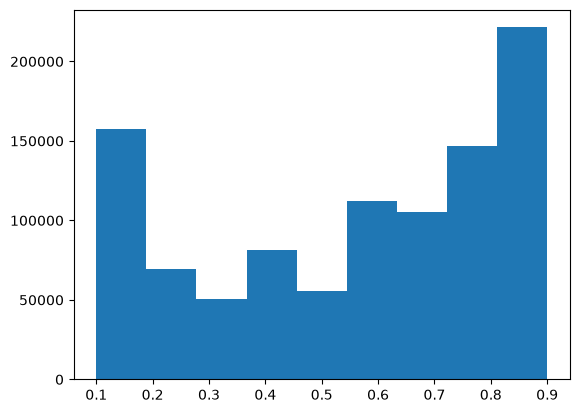

In [19]:
plt.hist(full_raw_data['income'], bins=9)
plt.show()

Мне кажется, что график может говорить о том, что верхнее и нижнее значения лимитированы, тк количество вхождений, попадающие под категорию слишком дисбалансное. При этом признак не непрерывный, поэтому проверить квантили не получится

Можно добавить проверки типа is_floored is_ceiled

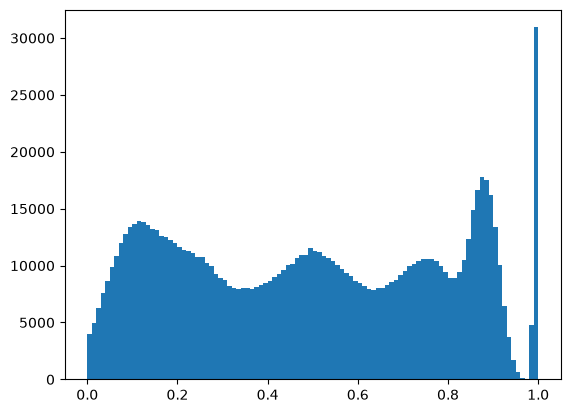

In [20]:
plt.hist(full_raw_data['name_email_similarity'], bins=100)
plt.show()

Можно увидеть сразу две лидирующие категории: те, у кого эмейл сильно похож на имя и те, у кого он почти не похож на имя - отдельно видно, что сильно заметна доля тех, у кого имя полностью соответствует эмейлу

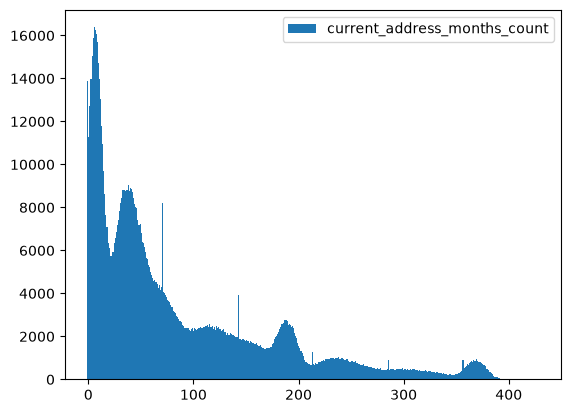

In [28]:
plt.hist(full_raw_data['current_address_months_count'], bins=423, label='current_address_months_count')
plt.legend()
plt.show()

Видно силовое распределение, которое возможно придется масштабировать через квадратный корень степень от 0 до 1 или натуральный логарифм

Меня напрягают эти пики поблизости 10, 50, после 100, около 200 и перед 400
Также странными кажутся выбросы, которые видны на графике

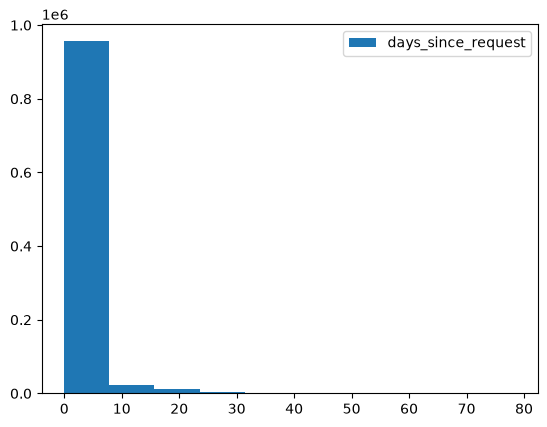

In [33]:
plt.hist(full_raw_data['days_since_request'], bins=10, label='days_since_request')
plt.legend()
plt.show()

Какой-то бешеный дисбаланс, который в целом адекватен для самого признака, но непонятно, как график прочитать

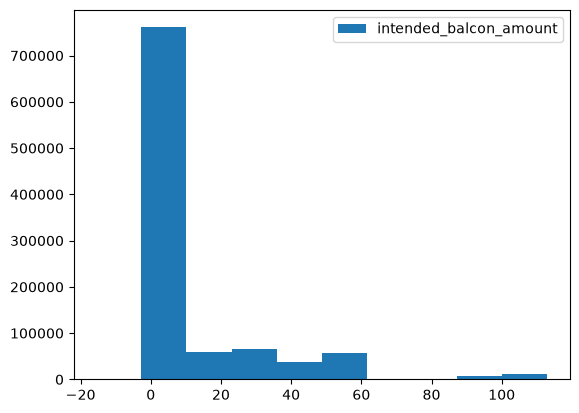

In [36]:
plt.hist(full_raw_data['intended_balcon_amount'], bins=10, label='intended_balcon_amount')
plt.legend()
plt.show()

Как-то надо проверить значения меньше 0. В целом распределение достаточно понятное, тк при создании счета он часто бывает фул пустым, а только небольшое количество людей туда закидывает деньги

Потенциально хороший признак, чтобы как-то прикинуть категорию сверхбогатых людей, либо дерзких скамеров

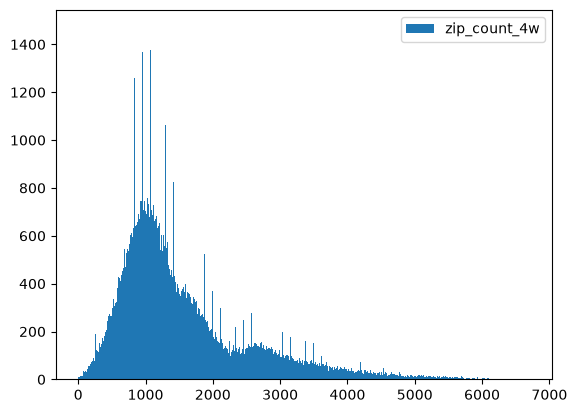

In [37]:
plt.hist(full_raw_data['zip_count_4w'], bins=6306, label='zip_count_4w')
plt.legend()
plt.show()

Количество заявок в пределах одного почтового индекса.

По графику видно две категории - та, что выше и больше, а вторая, что шире 

Надо понять, как отрисовывать сразу графики сразу всех месяцев через groupby

Идеи для feature engineering:
- Нужнно создать колонку is-1 для колонок, где может быть значащее значение -1
- Удалить -1 для того, чтобы не создавать спутанность и вывести название "неизвестно" в уровень категориального признака
- Подумать, что делать с выбросами?
- Разделить данные на обучение, валидационную и тестовую